# 02 - Entraînement, comparaison et résultats

**Prérequis : exécuter le notebook 01.** Ce notebook recharge les fichiers préparés,
vérifie leurs empreintes et utilise les transformations déjà ajustées. Il ne télécharge
pas les sources et ne réajuste pas le prétraitement sur validation ou test.

L'entraînement est désactivé par défaut (`RUN_TRAINING=False`) : cette séparation
ne lance pas la comparaison. Après vérification du protocole, mettre le drapeau à
`True` puis exécuter le notebook. Les quatre approches et les trois ablations sont
conservées ; le z-score est calculé sur NDVI uniquement.

Sans labels de stress, le critère de validation est un taux d'alerte cible fixé à l'avance,
pas une performance de détection. Précision, rappel, F1, délai et faux positifs agronomiques
restent non évaluables. Les six parcelles ne représentent pas toutes les oliveraies.

In [9]:
from pathlib import Path
import json, hashlib, random, copy, time, sys, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
import optuna
from IPython.display import display

ROOT=Path.cwd()
PREP=ROOT/'data/processed/model_inputs'
assert (PREP/'manifest.json').exists(), 'Exécuter d’abord 01_nettoyage_pretraitement.ipynb'
manifest=json.loads((PREP/'manifest.json').read_text(encoding='utf-8'))
assert manifest['format_version']==1
for name,expected in manifest['files_sha256'].items():
    assert hashlib.sha256((PREP/name).read_bytes()).hexdigest()==expected, 'Fichier modifié : '+name
CFG=manifest['config']; FEATURE_SETS=manifest['feature_sets']; SEED=manifest['seed']
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.set_num_threads(2)
data=pd.read_csv(PREP/'observations.csv')
for name in ['window_start','date','acquisition_date']:data[name]=pd.to_datetime(data[name])
assert len(data)==manifest['rows'] and not data.duplicated(['parcel_id','date']).any()
residual_file=np.load(PREP/'residuals.npz')
residuals={key:residual_file[key] for key in residual_file.files}
transformations=joblib.load(PREP/'transformations.joblib')
for key,features in FEATURE_SETS.items():assert residuals[key].shape==(len(data),len(features))
RUN_TRAINING=True
RUN_EXPERIMENT=RUN_TRAINING
READY=True
RUN_NAME='mon_essai_01'
OUT=ROOT/'outputs/experiments'/RUN_NAME
OUT.mkdir(parents=True,exist_ok=True)
META=OUT
morocco=ROOT/'data/raw/maroc'
print('Entrée vérifiée :',len(data),'fenêtres du calendrier,',int(data.usable.sum()),'observations utilisables.')
print('Entraînement activé :',RUN_TRAINING)
display(data.groupby('split').usable.agg(['size','sum']))

Entrée vérifiée : 888 fenêtres du calendrier, 613 observations utilisables.
Entraînement activé : True


,size,sum
split,,
test,222,191
train,444,216
val,222,206


## 1. Construire des fenêtres causales
Fenêtres 1, 3 ou 6 observations, sans franchir un split ni une lacune supérieure
à 15 jours. Les observations manquantes ne sont pas imputées. Le test final utilise
l'intersection des exemples disponibles pour les modèles sélectionnés.

In [10]:
def windows(df,residual,length):
    x=[]; indices=[]
    # groupe par split : aucune fenêtre partagée entre train, validation et test
    for _,g in df.groupby(['parcel_id','split'],sort=False):
        ix=g.index.to_numpy()
        for end in range(length-1,len(ix)):
            selected=ix[end-length+1:end+1]
            dates=df.loc[selected,'date']
            if dates.diff().dropna().dt.days.gt(CFG['max_gap_days']).any(): continue
            if not np.isfinite(residual[selected]).all(): continue
            x.append(residual[selected].ravel()); indices.append(ix[end])
    if not x: raise ValueError('Aucune fenêtre valide : vérifier dates, couverture et longueur')
    return np.array(x,dtype=np.float32),np.array(indices)

## Modèle 1 — z-score NDVI
Baseline statistique transparente : score = opposé du dernier résidu NDVI standardisé.
Une baisse inhabituelle donne un score élevé. Le seuil est choisi en validation.
Les hausses inhabituelles ne sont pas ciblées par cette baseline de déficit.
## Modèle 2 — Isolation Forest
Modèle non supervisé multivarié : isolement des fenêtres atypiques. Recherche sur
`n_estimators`, `max_samples` et `contamination` sans consulter le test.
## Modèle 3 — One-Class SVM
Frontière de normalité RBF ; recherche sur `gamma` et `nu`. Coût quadratique potentiel,
limitation déterministe de l'apprentissage à 5 000 fenêtres pour les deux modèles ML.
## Modèle 4 — autoencoder
Reconstruction d'une fenêtre aplatie, architecture dense, perte MSE, AdamW,
recherche sur dimension latente, learning rate, poids de régularisation et fenêtre.
Checkpoint choisi sur erreur de reconstruction des données de validation normales
connues (ou non étiquetées), jamais sur test. Ce choix suppose la majorité normale.

In [11]:
class Autoencoder(nn.Module):
    def __init__(self, size, latent):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(size,32),nn.ReLU(),nn.Linear(32,latent),nn.ReLU(),nn.Linear(latent,32),nn.ReLU(),nn.Linear(32,size))
    def forward(self,x): return self.net(x)
def fit_method(name,train,val,params):
    rng=np.random.default_rng(SEED)
    sample=train[rng.choice(len(train),min(5000,len(train)),replace=False)]
    if name=='zscore': return None,[]
    if name=='isolation': return IsolationForest(random_state=SEED,n_jobs=1,**params).fit(sample),[]
    if name=='svm': return OneClassSVM(kernel='rbf',**params).fit(sample),[]
    torch.manual_seed(SEED)
    model=Autoencoder(train.shape[1],params['latent'])
    optimizer=torch.optim.AdamW(model.parameters(),lr=params['lr'],weight_decay=params['weight_decay'])
    a=torch.tensor(train); b=torch.tensor(val)
    best=float('inf'); checkpoint=None; history=[]; stale=0
    for epoch in range(100):
        model.train(); losses=[]
        for batch in torch.randperm(len(a)).split(128):
            optimizer.zero_grad(); loss=((model(a[batch])-a[batch])**2).mean()
            loss.backward(); optimizer.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad(): v=((model(b)-b)**2).mean().item()
        history.append({'epoch':epoch,'train':float(np.mean(losses)),'validation':v})
        if v<best-1e-6: best=v; checkpoint=copy.deepcopy(model.state_dict()); stale=0
        else: stale+=1
        if stale>=10: break
    model.load_state_dict(checkpoint)
    return model,history
def score(name,model,x,n_features):
    if name=='zscore': return -x[:,-n_features]
    if name in ['isolation','svm']: return -model.score_samples(x)
    model.eval()
    with torch.no_grad(): return ((model(torch.tensor(x))-torch.tensor(x))**2).mean(dim=1).numpy()
def metrics(y,s,threshold):
    known=np.isfinite(y); y=y[known].astype(int); s=s[known]
    if not len(y): return dict(n_labelled=0,precision=None,recall=None,f1=None,ap=None,auc=None)
    pred=s>threshold
    tp=int(((y==1)&pred).sum()); fp=int(((y==0)&pred).sum()); fn=int(((y==1)&~pred).sum())
    precision=tp/(tp+fp) if tp+fp else None
    recall=tp/(tp+fn) if tp+fn else None
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None
    return dict(n_labelled=len(y),n_positive=int(y.sum()),tp=tp,fp=fp,fn=fn,
                precision=precision,recall=recall,f1=f1,
                ap=float(average_precision_score(y,s)) if len(set(y))==2 else None,
                auc=float(roc_auc_score(y,s)) if len(set(y))==2 else None,
                confusion=confusion_matrix(y,pred,labels=[0,1]).tolist())
def threshold_validation(scores,labels):
    thresholds=np.unique(np.quantile(scores,np.linspace(.80,.995,40)))
    labelled=np.isfinite(labels)
    supervised=labelled.sum()>0 and len(np.unique(labels[labelled]))==2
    def objective(t):
        if supervised: return metrics(labels,scores,t)['f1'] or 0.
        return -abs(float((scores>t).mean())-CFG['target_alert_rate'])
    selected=max(thresholds,key=objective)
    return float(selected),float(objective(selected)), 'F1 validation' if supervised else 'taux alerte cible (pas une performance)'

## 2. Optimisation et ablations sur validation
Budget : 12 essais TPE par méthode/ablation. Ablations : NDVI ; quatre indices ;
indices + température + humidité du sol. Le seuil est calibré sur validation uniquement.
Le paramètre contamination d'Isolation Forest est conservé, mais un seuil recalibré sur
le score peut rendre son effet redondant : ne pas interpréter ce paramètre comme un taux
de stress connu. En absence de labels, proximité du taux cible ≠ qualité agronomique.
Les périodes train/validation/test et le choix régional sont définis dans le notebook 01.

In [12]:
winners=[]; trials_log=[]
if READY and RUN_EXPERIMENT:
    assert not (OUT/'locked_protocol.json').exists(), 'Expérience déjà verrouillée : choisir un nouveau RUN_NAME.'
    data=data.reset_index(drop=True)
    assert {'train','val','test'}<=set(data.split), 'Splits temporels incomplets'
    ablations=FEATURE_SETS
    for ablation,features in ablations.items():
        residual=residuals[ablation]
        season=transformations[ablation]['season']
        scaler=transformations[ablation]['scaler']
        for name in ['zscore','isolation','svm','autoencoder']:
            if name=='zscore' and ablation!='ndvi': continue
            best_holder={}
            def objective(trial):
                length=trial.suggest_categorical('length',[1,3,6])
                x,ix=windows(data,residual,length)
                subset=data.loc[ix]; tr=subset.split.eq('train').to_numpy(); va=subset.split.eq('val').to_numpy()
                tr &= ~subset.label.eq(1).to_numpy()
                normal_val=va & ~subset.label.eq(1).to_numpy()
                confirmed_train=tr & subset.label.eq(0).to_numpy()
                confirmed_val=va & subset.label.eq(0).to_numpy()
                if confirmed_train.sum()>=20: tr=confirmed_train
                if confirmed_val.sum()>=5: normal_val=confirmed_val
                if tr.sum()<20 or normal_val.sum()<5: raise optuna.TrialPruned('Couverture insuffisante')
                params={}
                if name=='isolation': params=dict(n_estimators=trial.suggest_categorical('n_estimators',[100,250]),max_samples=trial.suggest_categorical('max_samples',[.5,1.]),contamination=trial.suggest_float('contamination',.01,.1))
                if name=='svm': params=dict(gamma=trial.suggest_float('gamma',1e-4,1.,log=True),nu=trial.suggest_float('nu',.01,.2))
                if name=='autoencoder': params=dict(latent=trial.suggest_categorical('latent',[2,4,8]),lr=trial.suggest_float('lr',1e-4,1e-2,log=True),weight_decay=trial.suggest_float('weight_decay',1e-6,1e-2,log=True))
                model,history=fit_method(name,x[tr],x[normal_val],params)
                scores=score(name,model,x[va],len(features))
                threshold,value,criterion=threshold_validation(scores,subset.loc[va,'label'].to_numpy(float))
                if not best_holder or value>best_holder['value']:
                    best_holder.update(value=value,name=name,ablation=ablation,features=features,params=params,length=length,threshold=threshold,criterion=criterion,model=model,history=history,season=season,scaler=scaler,x=x,ix=ix)
                return value
            study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
            study.optimize(objective,n_trials=CFG['trials'])
            study.trials_dataframe().to_csv(OUT/f'trials_{ablation}_{name}.csv',index=False)
            if best_holder: winners.append(best_holder)
    print('Modèles sélectionnés uniquement sur validation :',len(winners))
else: print('Entraînement non lancé : RUN_TRAINING=False. Les entrées sont prêtes.')

[I 2026-11-02 22:29:48,910] A new study created in memory with name: no-name-ad8691b1-a946-4729-8408-8206809cbebe
[I 2026-11-02 22:29:49,547] Trial 0 finished with value: -0.0012195121951219523 and parameters: {'length': 3}. Best is trial 0 with value: -0.0012195121951219523.
[I 2026-11-02 22:29:50,156] Trial 1 finished with value: -0.001456310679611654 and parameters: {'length': 1}. Best is trial 0 with value: -0.0012195121951219523.
[I 2026-11-02 22:29:50,773] Trial 2 finished with value: -0.0012195121951219523 and parameters: {'length': 3}. Best is trial 0 with value: -0.0012195121951219523.
[I 2026-11-02 22:29:51,378] Trial 3 finished with value: -0.0023809523809523864 and parameters: {'length': 6}. Best is trial 0 with value: -0.0012195121951219523.
[I 2026-11-02 22:29:52,117] Trial 4 finished with value: -0.001456310679611654 and parameters: {'length': 1}. Best is trial 0 with value: -0.0012195121951219523.
[I 2026-11-02 22:29:52,718] Trial 5 finished with value: -0.0023809523809

Modèles sélectionnés uniquement sur validation : 10


## 3. Évaluation et comparaison finale
Les choix sont verrouillés avant scoring du test. Aucun ajustement après consultation
du test. Les métriques sur vérité terrain restent nulles si aucune annotation confirmée
n'est disponible. Les alertes hors périodes de surveillance ne sont pas des faux positifs
connus. La stabilité interannuelle n'est pas mesurable sur une seule année de test.
Les tableaux descriptifs ne permettent pas de désigner un modèle comme meilleur en détection.

In [13]:
def event_metrics(pred):
    events=pd.read_csv(morocco/'events.csv'); coverage=pd.read_csv(morocco/'surveillance.csv')
    if coverage.empty: return {'event_precision':None,'event_recall':None,'event_f1':None,'mean_delay_days':None,'fp_per_parcel':None,'reason':'Surveillance exhaustive absente'}
    for c in ['start','end']: coverage[c]=pd.to_datetime(coverage[c])
    for c in ['onset','end','available_at']: events[c]=pd.to_datetime(events[c])
    assert not events.event_id.duplicated().any()
    lo,hi=pred.date.min(),pred.date.max()
    coverage=coverage[(coverage.end>=lo)&(coverage.start<=hi)].copy()
    coverage['start']=coverage.start.clip(lower=lo)
    coverage['end']=coverage.end.clip(upper=hi)
    episodes=[]; eligible=[]; parcels=set()
    for pid,group in pred.groupby('parcel_id'):
        cov=coverage[coverage.parcel_id.eq(pid)]
        if cov.empty: continue
        parcels.add(pid)
        monitored=group.date.map(lambda d: ((cov.start<=d)&(cov.end>=d)).any())
        dates=group.loc[monitored & group.alert,'date'].sort_values()
        last=None
        for d in dates:
            if last is None or (d-last).days>CFG['max_gap_days']: episodes.append((pid,d))
            last=d
        for row in events[events.parcel_id.eq(pid) & events.confirmed.eq(1)].itertuples():
            tol=pd.Timedelta(days=CFG['event_tolerance_days'])
            if ((cov.start<=row.onset-tol)&(cov.end>=row.end+tol)).any(): eligible.append(row)
    used=set(); delays=[]
    # Ordre chronologique et une seule correspondance par épisode et événement.
    for pid,d in sorted(episodes,key=lambda e:e[1]):
        candidates=[e for e in eligible if e.parcel_id==pid and e.event_id not in used and e.onset-pd.Timedelta(days=CFG['event_tolerance_days'])<=d<=e.end+pd.Timedelta(days=CFG['event_tolerance_days'])]
        if candidates:
            e=min(candidates,key=lambda e:abs((d-e.onset).days)); used.add(e.event_id); delays.append(max(0,(d-e.onset).days))
    tp=len(used); fp=len(episodes)-tp; fn=len(eligible)-tp
    return dict(event_precision=tp/len(episodes) if episodes else None,event_recall=tp/len(eligible) if eligible else None,event_f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None,mean_delay_days=float(np.mean(delays)) if delays else None,fp_per_parcel=fp/len(parcels) if parcels else None,n_events=len(eligible),n_episodes=len(episodes),n_monitored_parcels=len(parcels))
results=[]
if winners:
    # Verrouillage avant le premier calcul des scores de test.
    lock=OUT/'locked_protocol.json'
    if lock.exists(): raise RuntimeError('Expérience déjà verrouillée : conserver ce dossier et choisir un nouveau dossier outputs pour une nouvelle expérience.')
    choices=[{k:w[k] for k in ['name','ablation','params','length','threshold','criterion']} for w in winners]
    lock.write_text(json.dumps({'config':CFG,'choices':choices,'seed':SEED},indent=2))
    for split in ['test','spatial_test']:
        sets=[set(w['ix'][data.loc[w['ix'],'split'].eq(split)]) for w in winners]
        common=sorted(set.intersection(*sets))
        if not common: continue
        for w in winners:
            positions=np.array([np.flatnonzero(w['ix']==i)[0] for i in common])
            start=time.perf_counter(); s=score(w['name'],w['model'],w['x'][positions],len(w['features'])); seconds=time.perf_counter()-start
            pred=data.loc[common,['parcel_id','region','window_start','date','label']].copy()
            pred['score']=s; pred['alert']=s>w['threshold']
            tag=w['ablation']+'_'+w['name']
            pred.to_csv(OUT/f'predictions_{split}_{tag}.csv',index=False)
            row=dict(split=split,model=w['name'],ablation=w['ablation'],n=len(s),alert_rate=float(pred.alert.mean()),inference_seconds=seconds,**metrics(pred.label.to_numpy(float),s,w['threshold']),**event_metrics(pred))
            annual=pred.assign(year=pred.window_start.dt.year).groupby('year').alert.agg(['mean','count'])
            annual.to_csv(OUT/f'annual_{split}_{tag}.csv')
            row['annual_alert_rate_std']=float(annual['mean'].std()) if len(annual)>1 else None
            results.append(row)
    display(pd.DataFrame(results))
    pd.DataFrame(results).to_csv(OUT/'comparison.csv',index=False)
else: print('Comparaison indisponible : aucun entraînement réel effectué.')

,split,model,ablation,n,alert_rate,inference_seconds,n_labelled,precision,recall,f1,ap,auc,event_precision,event_recall,event_f1,mean_delay_days,fp_per_parcel,reason,annual_alert_rate_std
0,test,zscore,ndvi,81,0.000000,0.000025,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
1,test,isolation,ndvi,81,0.000000,0.009520,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
2,test,svm,ndvi,81,0.024691,0.000450,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
3,test,autoencoder,ndvi,81,0.024691,0.000469,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
4,test,isolation,indices,81,0.012346,0.021407,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
5,test,svm,indices,81,0.012346,0.000435,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
6,test,autoencoder,indices,81,0.000000,0.000424,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
7,test,isolation,meteo,81,0.000000,0.008652,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
8,test,svm,meteo,81,0.012346,0.000464,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None
9,test,autoencoder,meteo,81,0.012346,0.000410,0,None,None,None,None,None,None,None,None,None,None,Surveillance exhaustive absente,None


## 4. Courbes, modèles et sauvegarde
Les modèles, seuils, prédictions et courbes d'apprentissage ne sont écrits qu'après un
entraînement réel. Les résidus saisonniers et les scalers proviennent du notebook 01.
Le chronométrage porte sur le scoring en mémoire, hors téléchargement et prétraitement.

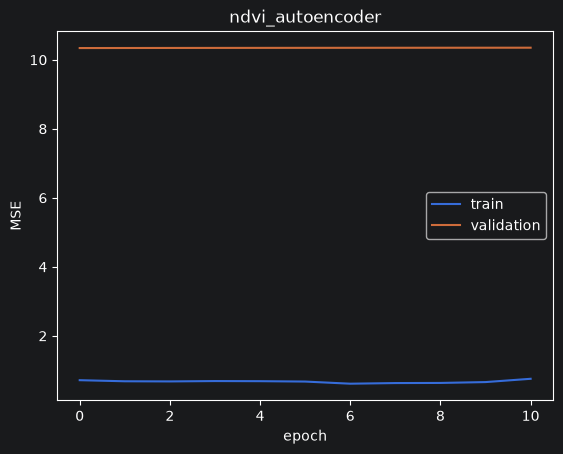

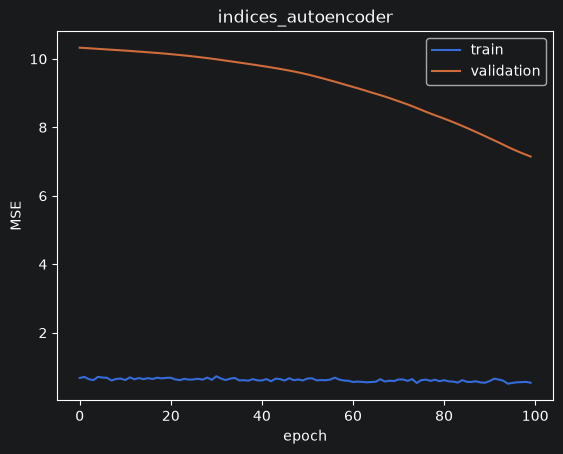

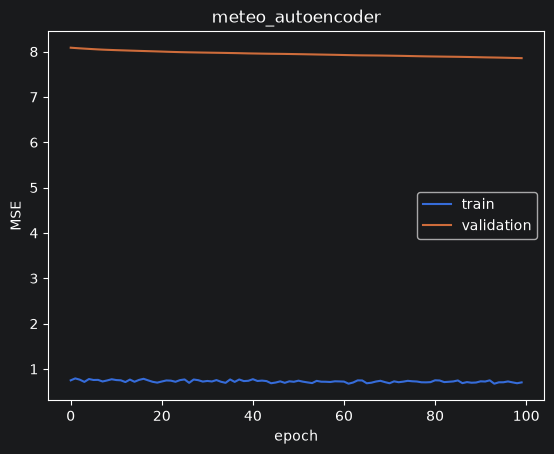

{'input_manifest_sha256': '380e42adb2b724d1854fc543e8cf010bff5d6b837856d80e26a5c27efd4a72e0',
 'training_requested': True,
 'trained_models': 10,
 'known_labels': 0,
 'comparison_rows': 10,
 'detection_metrics_evaluable': False,
 'seed': 42}

In [14]:
for w in winners:
    tag=w['ablation']+'_'+w['name']
    bundle={k:w[k] for k in ['name','features','params','length','threshold','season','scaler']}
    if w['name']=='autoencoder':
        torch.save(w['model'].state_dict(),OUT/f'{tag}.pt')
        pd.DataFrame(w['history']).to_csv(OUT/f'{tag}_learning.csv',index=False)
        pd.DataFrame(w['history']).set_index('epoch').plot(); plt.title(tag); plt.ylabel('MSE'); plt.show()
    else: bundle['model']=w['model']
    joblib.dump(bundle,OUT/f'{tag}.joblib')

status={'input_manifest_sha256':hashlib.sha256((PREP/'manifest.json').read_bytes()).hexdigest(),
        'training_requested':RUN_TRAINING,'trained_models':len(winners),
        'known_labels':int(data.label.notna().sum()),'comparison_rows':len(results),
        'detection_metrics_evaluable':bool(data.label.notna().any()),'seed':SEED}
(OUT/'status.json').write_text(json.dumps(status,indent=2,ensure_ascii=False),encoding='utf-8')
versions={name:importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','torch','optuna','joblib']}
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'packages':versions},indent=2))
display(status)
if not winners: print('Aucun modèle entraîné ; aucune performance ni prédiction produite.')

## 5. Contrôles et interprétation
Les petits exemples ci-dessous sont des tests de fonctions, pas des résultats sur les
oliveraies. Les données terrain restent indispensables pour mesurer la fiabilité des alertes.

In [15]:
assert metrics(np.array([1.,0.,np.nan]),np.array([2.,0.,9.]),1)['f1']==1
assert metrics(np.array([np.nan]),np.array([2.]),1)['precision'] is None
toy=pd.DataFrame({'parcel_id':['a']*6,'split':['train']*3+['test']*3,
                  'date':pd.date_range('2020-01-01',periods=6,freq='10D')})
wx,wi=windows(toy,np.arange(6,dtype=float).reshape(-1,1),3)
assert wi.tolist()==[2,5] and wx.tolist()==[[0.,1.,2.],[3.,4.,5.]]
if CFG['heldout_region'] is not None:
    a=set(data.loc[data.split.isin(['train','val']),'region'])
    b=set(data.loc[data.split.eq('spatial_test'),'region'])
    assert not a&b
print('Contrôles : métriques indisponibles non remplacées par zéro, fenêtres séparées, option régionale vérifiée.')

Contrôles : métriques indisponibles non remplacées par zéro, fenêtres séparées, option régionale vérifiée.
